# Conjunto B — a mesma perda, uma decisão por dia

## Cinco decisões, antes de qualquer import

| Decisão | Definição |
|---|---|
| Unidade de análise | Um dia de chegada do City Hotel, somando o alvo da mesma população de A |
| Instante da decisão | Início de cada semana operacional de 7 dias |
| Janela de observação | Série desde 01/07/2015 até a origem menos 16 dias; embargo conservador de 15 dias |
| Janela de desempenho | Os 7 dias a partir da origem; passo entre origens de 7 dias |
| População elegível | Todos os dias do horizonte, contando as reservas de A elegíveis em cada chegada |

## Mesmos custos e quantidade recomendada

`Y` é a quantidade diária de cancelamentos tardios/no-shows entre reservas ativas
na véspera, de 1 a 14 noites e criadas antes da chegada. `q` é a quantidade de vagas
de **primeira noite** a oferecer adicionalmente. Cada vaga abaixo de `Y` custa
R$ 400 de oportunidade; cada vaga acima de `Y` custa R$ 1.200 de compensação.

`L(Y,q) = 400 × max(Y-q,0) + 1.200 × max(q-Y,0)`.

O quantil ótimo é `400 / (400 + 1.200) = 0,25`. Ele é complementar ao limiar de A
porque o erro caro, aqui, é superestimar as vagas liberadas. São os mesmos valores
hipotéticos e as mesmas limitações: procura substituta, vaga por reserva,
primeira noite, sem simular capacidade real ou receita observada.

O total futuro de reservas ativas não é usado como variável: ele ainda é
desconhecido na origem semanal. A previsão é marginal, baseada no passado.
Na operação, a elegibilidade de cada reserva será conhecida na sua véspera.
Isso torna B um planejamento antecipado, diferente da ação individual de A.

## Fontes e execução

- [Enunciado](../fontes/TRABALHO_extraclasse.pdf).
- Antonio, Almeida e Nunes (2019), [artigo original](https://doi.org/10.1016/j.dib.2018.11.126).
- [TidyTuesday, 11/02/2020](https://github.com/rfordatascience/tidytuesday/tree/main/data/2020/2020-02-11), espelho dos dados e dicionário.
- Cópias e metadados em `../fontes/` e `../dados/proveniencia.json`.
- Rotinas compartilhadas auditáveis: [metodo.py](../src/metodo.py). Não é necessário executar outro notebook antes deste.
- Dependências: `../requirements.txt`; instruções locais: `../COMO_EXECUTAR.md`.

O artigo é distribuído sob CC BY. O espelho atribui os dados aos autores;
não presumimos uma licença CC0 independente. Consulte a documentação preservada
para atribuição e condições. Houve uso de IA; a especificação e suas revisões estão
no `.md` ao lado deste notebook.

## 1. A mesma população em outra unidade

Construir a série pela mesma função impede comparar problemas diferentes sem perceber. Não vamos contar todos os cancelamentos do arquivo.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidatas = [Path.cwd(), *Path.cwd().parents]
RAIZ = next(p for p in candidatas if (p / 'src/metodo.py').exists())
sys.path.insert(0, str(RAIZ / 'src'))
from metodo import *

plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
bruto, dados, filtros = carregar_dados()
serie = construir_serie(dados)

display(filtros)
print('Soma dos alvos individuais:', int(dados.is_canceled.sum()))
print('Soma da série:', int(serie.cancelamentos.sum()))
print('Pontos diários:', len(serie), '| ciclos semanais completos:', len(serie)//7)
display(serie.head(10))

,etapa,antes,depois,excluidas
0,Arquivo integral,119390,119390,0
1,Somente City Hotel,119390,79330,40060
2,Criada antes do dia da chegada,79330,76221,3109
3,Estadia planejada entre 1 e 14 noites,76221,75940,281
4,Ativa no fim da véspera,75940,44393,31547


Soma dos alvos individuais: 1155
Soma da série: 1155
Pontos diários: 793 | ciclos semanais completos: 113


,cancelamentos,exposicao,ultimo_rotulo
data,,,
2015-07-01,1,66,2015-07-07
2015-07-02,2,3,2015-07-06
2015-07-03,0,10,2015-07-11
2015-07-04,1,10,2015-07-09
2015-07-05,0,0,NaT
2015-07-06,2,3,2015-07-08
2015-07-07,3,5,2015-07-18
2015-07-08,0,24,2015-07-14
2015-07-09,1,2,2015-07-15


**Leitura:** as duas somas devem ser idênticas. Mais de 100 pontos e mais de dois ciclos semanais são necessários, mas não garantem previsibilidade ou qualidade dos registros.

## 2. Datas, exposição e zeros

Dias sem eventos elegíveis são diferentes de dias com reservas mas sem cancelamentos. O calendário completo é necessário para preservar o significado de uma defasagem de sete dias.

Datas duplicadas no índice: 0
Dias sem reserva elegível: 6
Dias com alvo zero: 298


,cancelamentos,exposicao,ultimo_rotulo
data,,,
2015-07-05,0,0,NaT
2015-07-12,0,0,NaT
2015-07-14,0,0,NaT
2015-07-19,0,0,NaT
2015-07-21,0,0,NaT
2015-07-24,0,0,NaT


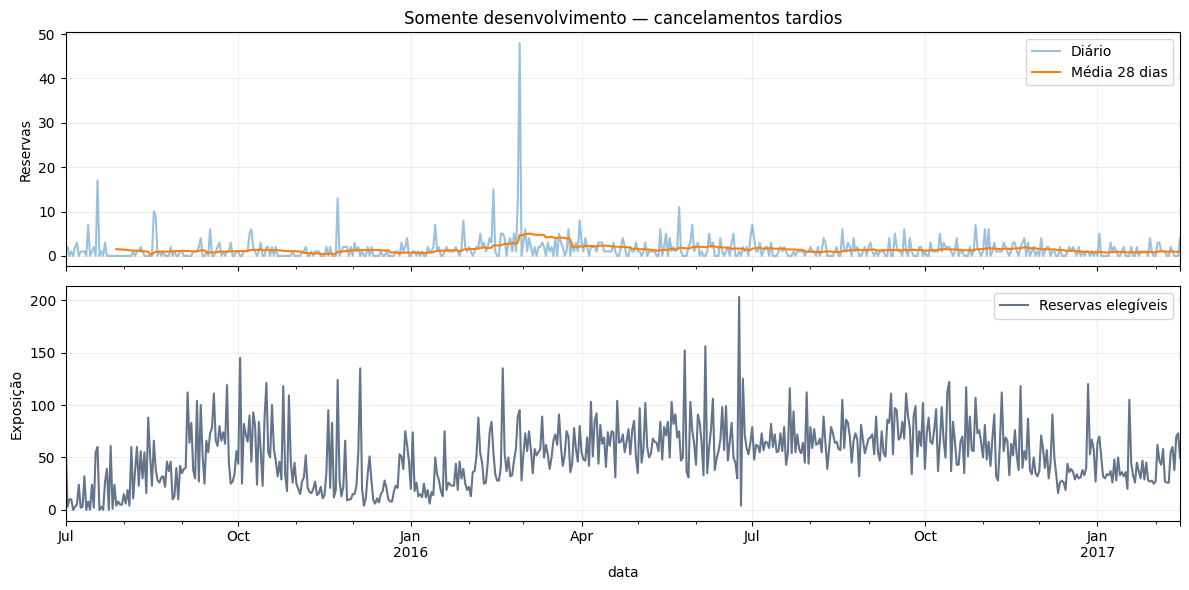

In [2]:
print('Datas duplicadas no índice:', serie.index.duplicated().sum())
print('Dias sem reserva elegível:', int(serie.exposicao.eq(0).sum()))
print('Dias com alvo zero:', int(serie.cancelamentos.eq(0).sum()))
display(serie.loc[serie.exposicao.eq(0)])
desenvolvimento = serie.loc[serie.index <= '2017-02-14'].copy()
fig,eixos=plt.subplots(2,1,figsize=(12,6),sharex=True)
desenvolvimento.cancelamentos.plot(ax=eixos[0],alpha=0.45,label='Diário')
desenvolvimento.cancelamentos.rolling(28,min_periods=28).mean().plot(ax=eixos[0],label='Média 28 dias')
desenvolvimento.exposicao.plot(ax=eixos[1],color='#64748b',label='Reservas elegíveis')
eixos[0].legend();eixos[1].legend();eixos[0].set_title('Somente desenvolvimento — cancelamentos tardios')
eixos[0].set_ylabel('Reservas');eixos[1].set_ylabel('Exposição');plt.tight_layout();plt.show()

**Leitura:** o alvo é uma contagem discreta e contém zeros. A exposição explica
parte da variação, mas só é observada na véspera de cada dia; não será usada
como informação futura no planejamento semanal. Zeros são condicionais à
cobertura da base, sem prova externa de ausência de falhas do sistema.

## 3. Decomposição semanal

Uma decomposição é diagnóstico, não evidência de que um modelo preveja bem. Usamos somente dados de desenvolvimento e uma forma aditiva porque há zeros.

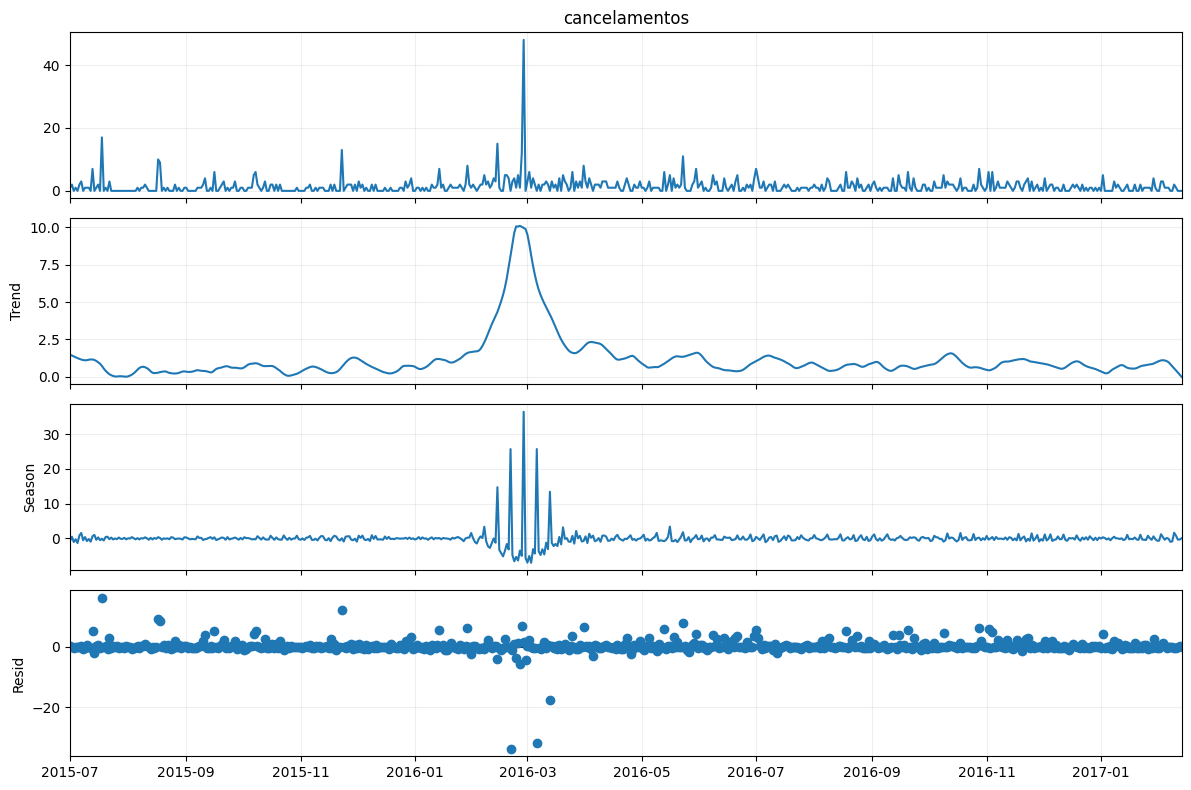

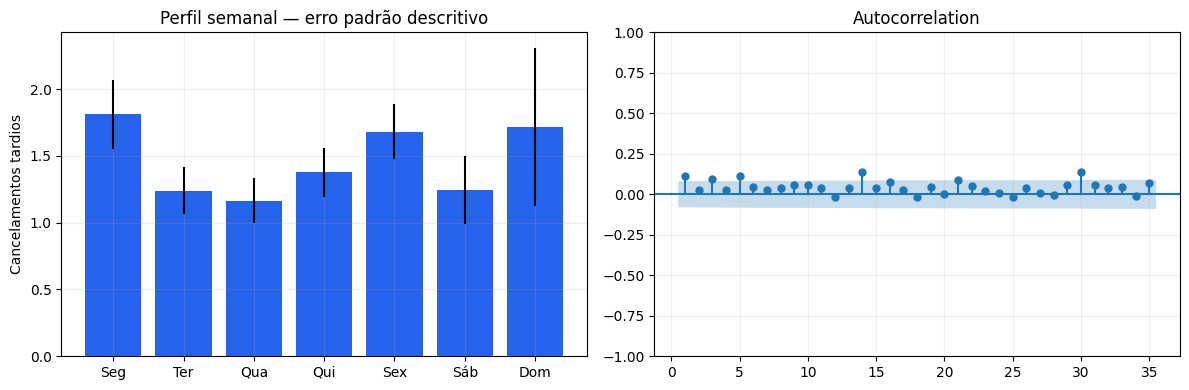

,mean,std,count,erro_padrao
data,,,,
0,1.8118,2.3629,85,0.2563
1,1.2381,1.6104,84,0.1757
2,1.1647,1.5341,85,0.1664
3,1.3765,1.6972,85,0.1841
4,1.6824,1.8785,85,0.2038
5,1.2471,2.3346,85,0.2532
6,1.7176,5.4611,85,0.5923


In [3]:
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf
desenvolvimento_seguro = serie.loc[:'2017-02-13','cancelamentos'].astype(float)
decomposicao = STL(desenvolvimento_seguro,period=7,robust=True).fit()
figura=decomposicao.plot();figura.set_size_inches(12,8);plt.tight_layout();plt.show()
fig,eixos=plt.subplots(1,2,figsize=(12,4))
perfil=desenvolvimento_seguro.groupby(desenvolvimento_seguro.index.dayofweek).agg(['mean','std','count'])
perfil['erro_padrao']=perfil['std']/np.sqrt(perfil['count'])
eixos[0].bar(range(7),perfil['mean'],yerr=perfil['erro_padrao'],color='#2563eb')
eixos[0].set_xticks(range(7),['Seg','Ter','Qua','Qui','Sex','Sáb','Dom'])
eixos[0].set(title='Perfil semanal — erro padrão descritivo',ylabel='Cancelamentos tardios')
plot_acf(desenvolvimento_seguro,lags=35,ax=eixos[1],zero=False)
plt.tight_layout();plt.show();display(perfil)

**Leitura:** a sazonalidade de sete dias é uma hipótese operacional a testar
contra um baseline que repete a semana. A decomposição pode separar oscilações
mesmo em uma série pouco previsível. As barras são descrições amostrais;
dependência temporal invalida uma leitura automática como intervalo de confiança.
A decomposição multiplicativa não é aplicada a contagens com zeros, e não
acrescentamos uma constante arbitrária apenas para fazê-la funcionar.

## 4. Resíduos e desenho da origem móvel

A previsão precisa atravessar o atraso dos dados. Sete dias operacionais não significam que o modelo só precisa prever sete passos desde a última observação utilizável.

In [4]:
from statsmodels.stats.diagnostic import acorr_ljungbox
display(acorr_ljungbox(decomposicao.resid,lags=[7,14],return_df=True))
origens = origens_b()
display(pd.DataFrame([
    {'parte':k,'origens':len(v),'primeira':v.min(),'ultima':v.max(),
     'ultimo_alvo':v.max()+pd.Timedelta(days=6)} for k,v in origens.items()]))
exemplo = origens['teste'][0]
limite=exemplo-pd.Timedelta(days=ATRASO)
print('Exemplo de origem:',exemplo.date())
print('Último dia de treino:',(limite-pd.Timedelta(days=1)).date())
print('Passos internos:',ATRASO+HORIZONTE,'| dias operacionais:',HORIZONTE)
print('Duas bordas finais sem semana completa: 30 e 31/08/2017')

,lb_stat,lb_pvalue
7,19.8005,0.0060
14,63.7865,0.0000


,parte,origens,primeira,ultima,ultimo_alvo
0,calibracao,32,2016-01-01,2016-08-05,2016-08-11
1,validacao,23,2016-09-01,2017-02-02,2017-02-08
2,teste,26,2017-03-01,2017-08-23,2017-08-29


Exemplo de origem: 2017-03-01
Último dia de treino: 2017-02-13
Passos internos: 22 | dias operacionais: 7
Duas bordas finais sem semana completa: 30 e 31/08/2017


**Leitura:** o treino usa somente coortes totalmente maduras. Para a origem de
março, o histórico para em fevereiro e a previsão atravessa 15 dias sem rótulos
antes da semana avaliada. Não se preenche esse trecho com valores reais.
O Ljung–Box é diagnóstico descritivo dos resíduos da decomposição, não uma
avaliação de previsão nem um certificado de independência.

Janeiro a agosto/2016 fornece erros para a distribuição; setembro/2016 a
fevereiro/2017 seleciona o modelo. As bordas desses blocos respeitam 15 dias
para maturação antes da fase seguinte. Março a 29/agosto/2017 é teste final:
26 semanas sem sobreposição. Todo modelo usa as mesmas origens e horizonte.

<!-- RESULTADOS_B1 -->

## Conclusão do diagnóstico

Somar a população de A preserva exatamente **1155 eventos
positivos em 793 dias**. A série contém muitos zeros e exposição
variável; contagens grandes isoladas não podem ser interpretadas apenas como
mudança no risco individual. O período inicial tem seis dias sem evento elegível,
preservados com zero. Não há recorte silencioso das bordas para melhorar métricas.

A avaliação tem 32 origens para calibrar os erros, 23 para selecionar modelos
e **26 semanas não sobrepostas no teste**, totalizando 182 dias. Em cada origem,
o modelo prevê 22 passos desde o fim do treino: 15 de embargo e 7 de operação.
Não há observações reais do trecho intermediário usadas na previsão.

O diagnóstico justifica experimentar estrutura semanal; ele não demonstra que
SARIMA será superior. Essa afirmação depende do próximo notebook.